# Project 1, 665 extension: frozen features or fine-tuning?

For the same pretrained ViT, what do we gain or lose by updating its representation rather than training only a linear head?
Needs A6-H (P1_A) and your B1 and B3 photos (P1_B). No new photos, data, or deep-model training.

On Colab, start in a fresh session (Runtime > Disconnect and delete runtime in the previous notebook), and finish the Google Drive pop-up that the first cell opens.

Write your own training, evaluation, and visualization code (PyTorch, torchvision, OpenCV, scikit-learn, timm). A1 to A5 use no pretrained weights. AI tools may help you study; they may not write your code or report.

Library functions are listed in each step below, and in full in the handout's Appendix A.

In [1]:
import os, sys
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:                 # every notebook of the project shares one folder on your Google Drive
    from google.colab import drive
    try:                     # a sign-in pop-up opens: finish it within 10 minutes (Colab's default is 2)
        drive.mount('/content/drive', timeout_ms=600_000)
    except Exception as e:
        raise RuntimeError('Google Drive did not mount. Run this cell again and finish the sign-in pop-up, '
                           'with the same Google account in every notebook.') from e
ROOT = os.environ.get('P1_ROOT') or ('/content/drive/MyDrive/p1' if IN_COLAB else os.path.abspath('p1'))
os.environ['P1_ROOT'] = ROOT
os.makedirs(ROOT, exist_ok=True)
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
print('project folder:', ROOT)
assert os.path.exists(os.path.join(ROOT, 'p1_utils.py')), 'Run P1_0_Setup_and_Data.ipynb first: it writes p1_utils.py.'
from p1_utils import *
print_versions()

Mounted at /content/drive
project folder: /content/drive/MyDrive/p1
p1_utils: project folder /content/drive/MyDrive/p1 | OpenCV 4.14.0 | Colab: True
versions: python 3.13.18, torch 2.14.1+cpu, torchvision 0.29.1+cpu, timm 1.0.30, numpy 2.4.6, scikit-learn 1.6.1, pandas 2.2.3, matplotlib 3.10.0, pillow 11.3.0, pillow-heif 1.8.1, opencv 4.14.0, gpu none


{'python': '3.13.18',
 'torch': '2.14.1+cpu',
 'torchvision': '0.29.1+cpu',
 'timm': '1.0.30',
 'numpy': '2.4.6',
 'scikit-learn': '1.6.1',
 'pandas': '2.2.3',
 'matplotlib': '3.10.0',
 'pillow': '11.3.0',
 'pillow-heif': '1.8.1',
 'opencv': '4.14.0',
 'gpu': 'none'}

In [2]:
import torch, torch.nn as nn, torch.nn.functional as F
DEV = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
print('device:', DEV)
MY_CLASSES = ['bicycle', 'bottle', 'chair', 'car', 'cat']     # TODO: your five classes (same in every notebook)

device: cpu


In [3]:
X64, y, img_id, is_test = load_crops(64)          # cached by P1_0
idx_train, idx_val, idx_test = make_splits(img_id, is_test)
HAS_PERSON = person_flags()                       # leave these crops out of every figure
print(len(idx_train), 'train,', len(idx_val), 'validation,', len(idx_test), 'test crops')

7541 train, 797 validation, 8381 test crops


In [4]:
try:                                              # your classes and helpers, written in P1_A
    from my_models import *
except ImportError:
    print('my_models.py not found yet: write it in P1_A_Classifier_Ladder')

In [5]:
# Helpers for this notebook, built on my_models.py from P1_A: the same classes, checkpoint files, statistics and
# preprocessing as P1_A (a2_stats.npz + a2_concat.pt, a4_stats.npz + a4.pt, a6_h_stats.npz + a6_h.pt).
import os
from pathlib import Path
import timm
from my_models import A2Linear, A4ResNet, A6ViT, preprocess_a2, preprocess_a4, preprocess_a6

NUM_CLASSES = 19
A6_NAME = "vit_tiny_patch16_224.augreg_in21k_ft_in1k"


def mean_per_class_accuracy(y_true, predictions, classes=range(19)):
    """C^-1 sum_c correct_c / total_c; predictions are labels or (N, 19) scores, always among all 19 classes."""
    y_true = np.asarray(y_true)
    predictions = np.asarray(predictions)
    if predictions.ndim == 2:
        predictions = predictions.argmax(axis=1)
    per_class = {c: float((predictions[y_true == c] == c).mean()) for c in list(classes)}
    return float(np.mean(list(per_class.values()))), per_class


def count_params(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)


def resize_to(images, size):
    images = np.asarray(images)
    if images.shape[1:3] == (size, size):
        return images
    return np.stack([cv2.resize(i, (size, size), interpolation=cv2.INTER_AREA) for i in images])


def a6_stats(model):
    return np.asarray(model.pretrained_cfg["mean"], np.float32), np.asarray(model.pretrained_cfg["std"], np.float32)


@torch.no_grad()
def predict_proba(model, images, prep, device, idx=None, batch_size=128):
    """Softmax over all 19 classes for images[idx] (uint8, N x H x W x 3), batch by batch."""
    model.eval()
    images = images if isinstance(images, np.ndarray) else np.stack(images)
    idx = np.arange(len(images)) if idx is None else np.asarray(idx)
    out = []
    for s in range(0, len(idx), batch_size):
        xb = prep(images[idx[s:s + batch_size]]).to(device)
        out.append(F.softmax(model(xb).float(), dim=1).cpu())
    return torch.cat(out).numpy() if out else np.zeros((0, NUM_CLASSES), np.float32)


def load_model(name, ckpt_dir, device):
    """'A2' (concatenated features), 'A4', 'A6-H' or 'A6-H-repaired', each with its P1_A preprocessing.
    Returns (model in eval mode, prep), where prep maps uint8 images (N, H, W, 3) to the model's input tensor."""
    ck = Path(ckpt_dir)
    state = lambda f: torch.load(ck / f, map_location="cpu", weights_only=True)
    if name == "A2":
        stats = dict(np.load(ck / "a2_stats.npz"))
        sd = state("a2_concat.pt")
        model = A2Linear(sd["linear.weight"].shape[1])
        model.load_state_dict(sd)
        prep = lambda imgs: preprocess_a2(resize_to(imgs, 64), stats, "concat")
    elif name == "A4":
        st = np.load(ck / "a4_stats.npz")
        mean, std = st["mean"], st["std"]
        model = A4ResNet()
        model.load_state_dict(state("a4.pt"))
        prep = lambda imgs: preprocess_a4(resize_to(imgs, 64), mean, std)
    elif name in ("A6-H", "A6-H-repaired"):
        st = np.load(ck / "a6_h_stats.npz")
        mean, std = st["mean"], st["std"]
        model = A6ViT(pretrained=False)
        model.load_state_dict(state("a6_h.pt" if name == "A6-H" else "a6_h_repaired.pt"))
        prep = lambda imgs: preprocess_a6(imgs, mean, std, "cpu")
    else:
        raise ValueError(name)
    return model.to(device).eval(), prep

In [6]:
X224, _, _, _ = load_crops(224)     # the frozen encoder takes 224 px crops, like A6-H (X64 is not enough)
# Kept as uint8 and converted one batch at a time: all of it as float32 is 10 GB, more than Colab's free RAM.
import time, timm
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
CHOSEN_FACTOR = 'distance'          # same as P1_B; only the rotation series is used here
my_idx = [CLASSES.index(c) for c in MY_CLASSES]


def sync():
    if str(DEV).startswith("cuda"):
        torch.cuda.synchronize()


def acc5(true, pred):
    true, pred = np.asarray(true), np.asarray(pred)
    present = [c for c in my_idx if (true == c).any()]
    return mean_per_class_accuracy(true, pred, classes=present)

In [8]:
# The ORIGINAL checkpoint (not A6-H), frozen entirely (normalization and position embeddings included), in eval mode.
# Its feature is the final normalized class token, the input of the head: with num_classes=0, timm returns exactly that.
enc = timm.create_model(A6_NAME, pretrained=True, num_classes=0).to(DEV).eval()
for p in enc.parameters():
    p.requires_grad_(False)
f_mean, f_std = a6_stats(enc)                    # the checkpoint's own mean and std, as for A6-H
print("frozen encoder:", f"{count_params(enc):,}", "parameters, trainable:", count_params(enc, trainable_only=True))


@torch.no_grad()
def extract(images, idx=None, flip=False, batch_size=128):
    images = images if isinstance(images, np.ndarray) else np.stack(images)
    idx = np.arange(len(images)) if idx is None else np.asarray(idx)
    out = []
    for s in range(0, len(idx), batch_size):
        x = preprocess_a6(images[idx[s:s + batch_size]], f_mean, f_std, device=DEV)
        if flip:
            x = x.flip(3)
        out.append(enc(x).float().cpu())
    return torch.cat(out)


with torch.no_grad():                            # the feature is the normalized class token
    x = preprocess_a6(X224[idx_val[:4]], f_mean, f_std, device=DEV)
    assert torch.allclose(enc(x), enc.forward_features(x)[:, 0], atol=1e-5)

sync(); t0 = time.perf_counter()
F_train = extract(X224, idx_train)               # each training crop once, and its flip once
F_train_flip = extract(X224, idx_train, flip=True)
F_val = extract(X224, idx_val)                   # validation, test and photos: unflipped view only
F_test = extract(X224, idx_test)
sync(); extract_seconds = time.perf_counter() - t0
print(f"VOC features {tuple(F_train.shape)} (+ flips), {tuple(F_val.shape)}, {tuple(F_test.shape)} "
      f"in {extract_seconds:.0f} s")

X1_224, y1, paths1 = load_photo_folder(os.path.join(PHOTO_DIR, 'B1'), 224)
B3_DIR = os.path.join(PHOTO_DIR, 'B3')
rot_recs = [r for r in load_b3_series(B3_DIR, 224, CHOSEN_FACTOR) if r['factor'] == 'rotation']
X_rot = np.stack([r["image"] for r in rot_recs])
y_rot = np.array([r["cls"] for r in rot_recs])
F_b1, F_rot = extract(X1_224), extract(X_rot)
print(len(y1), "B1 photos,", len(rot_recs), "B3 rotation images")

frozen encoder: 5,524,416 parameters, trainable: 0
VOC features (7541, 192) (+ flips), (797, 192), (8381, 192) in 1072 s
50 B1 photos, 40 B3 rotation images


In [9]:
# Reload check for A6-H, before comparing with it: VOC test mean per-class accuracy (19 classes) must match Table 1.
a6h, prep_a6h = load_model("A6-H", CKPT_DIR, DEV)
A6H_TEST = predict_proba(a6h, X224, prep_a6h, DEV, idx=idx_test)
acc, _ = mean_per_class_accuracy(y[idx_test], A6H_TEST)
a6h_saved = np.load(Path(CKPT_DIR) / "a6_h_test.npz")
print(f"A6-H test {acc:.2%} | Table 1 {float(a6h_saved['mean_per_class_acc']):.2%}")
assert abs(acc - float(a6h_saved["mean_per_class_acc"])) < 1e-3, "preprocessing differs from P1_A"

A6-H test 92.20% | Table 1 92.20%


In [10]:
# A new 19-way linear head on the frozen features, with A6-H's head settings: created right after torch.manual_seed(1);
# cross-entropy, AdamW, lr 1e-3, weight decay 1e-2, batch 32, 5 epochs, best validation epoch kept. Each epoch uses the
# original or the flipped feature of each training crop with probability 0.5. Only the head trains.
torch.manual_seed(1)
head = nn.Linear(192, 19).to(DEV)
opt = torch.optim.AdamW(head.parameters(), lr=1e-3, weight_decay=1e-2)
torch.manual_seed(0)
rng = np.random.default_rng(0)
Ftr, Ftr_flip, Fv = F_train.to(DEV), F_train_flip.to(DEV), F_val.to(DEV)
ytr = torch.from_numpy(y[idx_train]).long().to(DEV)
n = len(idx_train)
best_acc, best_epoch, best_state = -1.0, 0, None
head_hist = []
sync(); t0 = time.perf_counter()
for epoch in range(1, 6):
    head.train()
    use_flip = torch.rand(n, device=DEV) < 0.5
    feats = torch.where(use_flip[:, None], Ftr_flip, Ftr)
    order = torch.from_numpy(rng.permutation(n)).to(DEV)
    total = 0.0
    for s in range(0, n, 32):
        b = order[s:s + 32]
        loss = F.cross_entropy(head(feats[b]), ytr[b])
        opt.zero_grad(); loss.backward(); opt.step()
        total += loss.item() * len(b)
    head.eval()
    with torch.no_grad():
        val_acc, _ = mean_per_class_accuracy(y[idx_val], head(Fv).argmax(1))
    head_hist.append((total / n, val_acc))
    if val_acc > best_acc:
        best_acc, best_epoch = val_acc, epoch
        best_state = {k: v.detach().cpu().clone() for k, v in head.state_dict().items()}
    print(f"frozen head epoch {epoch} | loss {total / n:.4f} | val mean-class acc {val_acc:.2%}")
sync(); head_seconds = time.perf_counter() - t0
head.load_state_dict(best_state)
head.eval()
torch.save(best_state, Path(CKPT_DIR) / "a6_frozen_head.pt")
print(f"best epoch {best_epoch}, validation {best_acc:.2%}, head fitting {head_seconds:.1f} s")

frozen head epoch 1 | loss 0.9720 | val mean-class acc 86.73%
frozen head epoch 2 | loss 0.3477 | val mean-class acc 87.45%
frozen head epoch 3 | loss 0.2776 | val mean-class acc 88.25%
frozen head epoch 4 | loss 0.2418 | val mean-class acc 86.64%
frozen head epoch 5 | loss 0.2172 | val mean-class acc 87.58%
best epoch 3, validation 88.25%, head fitting 0.8 s


model,VOC test (19),B1 (5),total parameters,trainable parameters,training cost
A6-H (fine-tuned),92.2%,86.0%,"5,528,083","5,528,083",fine-tuning 167 s (Tesla T4)
frozen features + linear head,88.6%,90.0%,"5,528,083","3,667",feature extraction 1072 s + head fitting 0.8 s (cpu)


A6-H {'0': np.float64(0.9), '30': np.float64(0.8), '90': np.float64(0.6), '180': np.float64(0.7)}
A6-frozen {'0': np.float64(0.8), '30': np.float64(0.8), '90': np.float64(0.6), '180': np.float64(0.7)}


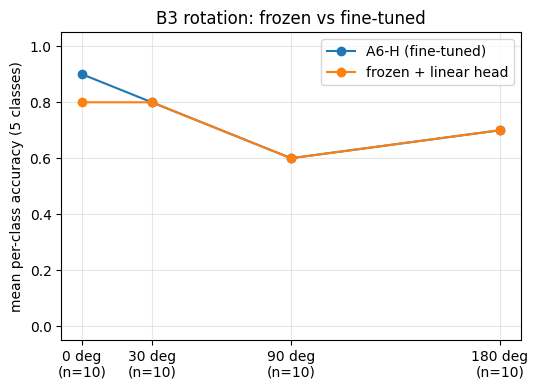

wrote 40 rows to /content/drive/MyDrive/p1/results/b3_results.csv, and kept 270 rows of other models


In [11]:
# Frozen-feature model vs A6-H (before the B5 repair): VOC test (19 classes) and B1 (5 classes) mean per-class accuracy,
# parameters, training cost, and the B3 rotation series.
@torch.no_grad()
def frozen_proba(feats):
    return F.softmax(head(feats.to(DEV)), dim=1).cpu().numpy()


hardware = torch.cuda.get_device_name(0) if str(DEV).startswith("cuda") else str(DEV)
frozen_total = count_params(enc) + count_params(head)
results = pd.DataFrame([
    {"model": "A6-H (fine-tuned)",
     "VOC test (19)": mean_per_class_accuracy(y[idx_test], A6H_TEST)[0],
     "B1 (5)": acc5(y1, predict_proba(a6h, X1_224, prep_a6h, DEV).argmax(1))[0],
     "total parameters": count_params(a6h), "trainable parameters": count_params(a6h, trainable_only=True),
     "training cost": f"fine-tuning {float(a6h_saved['training_seconds']):.0f} s ({str(a6h_saved['hardware'])})"},
    {"model": "frozen features + linear head",
     "VOC test (19)": mean_per_class_accuracy(y[idx_test], frozen_proba(F_test))[0],
     "B1 (5)": acc5(y1, frozen_proba(F_b1).argmax(1))[0],
     "total parameters": frozen_total, "trainable parameters": count_params(head),
     "training cost": f"feature extraction {extract_seconds:.0f} s + head fitting {head_seconds:.1f} s ({hardware})"}])
results.to_csv(Path(RESULTS_DIR) / "665_frozen_vs_finetuned.csv", index=False)
display(results.style.format({"VOC test (19)": "{:.1%}", "B1 (5)": "{:.1%}", "total parameters": "{:,}",
                              "trainable parameters": "{:,}"}).hide(axis="index"))

# Rotation plot: mean per-class accuracy over our five classes at each angle, both models
rot_probs = {"A6-H": predict_proba(a6h, X_rot, prep_a6h, DEV), "A6-frozen": frozen_proba(F_rot)}
angles = B3_FACTORS["rotation"]
fig, ax = plt.subplots(figsize=(5.5, 4))
for name, probs in rot_probs.items():
    accs, ns = [], []
    for a in angles:
        sel = [i for i, r in enumerate(rot_recs) if r["condition"] == a]
        accs.append(acc5(y_rot[sel], probs[sel].argmax(1))[0])
        ns.append(len(sel))
    ax.plot([int(a) for a in angles], accs, "-o", label="A6-H (fine-tuned)" if name == "A6-H" else "frozen + linear head")
    print(name, dict(zip(angles, np.round(accs, 2))))
ax.set_xticks([int(a) for a in angles])
ax.set_xticklabels([f"{a} deg\n(n={k})" for a, k in zip(angles, ns)])
ax.set(ylim=(-0.05, 1.05), ylabel="mean per-class accuracy (5 classes)", title="B3 rotation: frozen vs fine-tuned")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(Path(RESULTS_DIR) / "665_rotation.png", dpi=150)
plt.show()

# The frozen model's rotation rows go into b3_results.csv as 'A6-frozen' (rows of A2, A4 and A6-H already there are kept)
write_b3_csv(b3_rows(rot_recs, 'A6-frozen', rot_probs["A6-frozen"]), os.path.join(RESULTS_DIR, 'b3_results.csv'))